**Data Generation and Preparation**

1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

2. Generate Cattle-level Risk Factor Data

In [2]:

np.random.seed(42)
n = 10000

# Simulate extended risk factor dataset for Bovine respiratory disease (BRD)
df = pd.DataFrame({
    "age": np.random.normal(10, 2, n).clip(6, 14),  # months
    "weight": np.random.normal(500, 100, n).clip(350, 800),  # lbs
    "transport_distance": np.random.normal(500, 200, n).clip(50, 1500),  # miles
    "transit_time": np.random.normal(12, 3, n).clip(1, 24),  # hours
    "ambient_temp": np.random.normal(61, 20, n).clip(1, 104),  # °F
    "arrival_temp": np.random.normal(102.8, 2.0, n).clip(99.2, 105.8),  # °F
    "dust": np.random.randint(1, 5, n),
    "humidity": np.random.normal(60, 20, n).clip(20, 100),
    "comingling": np.random.choice([0, 1], size=n, p=[0.2, 0.8]),
    "season": np.random.choice(["Winter", "Spring", "Summer", "Fall"], size=n, p=[0.3, 0.2, 0.1, 0.4]),
    "preconditioning": np.random.choice([0, 1], size=n, p=[0.7, 0.3]),
    "genetic_resilience": np.random.normal(5, 2, n).clip(1, 9.9),
    "recent_weaning": np.random.choice([0, 1], size=n, p=[0.3, 0.7]),
    "sex": np.random.choice(["Male", "Female"], size=n),
    "nutrition": np.random.normal(5, 2, n).clip(1, 9.9),
    "brd_pathogen_positive": np.random.choice([0, 1], size=n, p=[0.6, 0.4]),
    "immune_status": np.random.normal(5, 2, n).clip(1, 9.9),
    "previous_health": np.random.normal(5, 2, n).clip(1, 9.9),
    "vaccinated": np.random.choice([0, 1], size=n, p=[0.3, 0.7]),
    "housing_type": np.random.choice(["Open", "Shelter", "Confined"], size=n),
    "breed": np.random.choice(["Angus", "Hereford", "Brahman", "Mixed"], size=n),
    "temperament": np.random.choice(["Docile", "Restless", "Aggressive"], size=n),
})

In [3]:
df['late_castration'] = np.where(
    (df['sex'] == 'Male') & (np.random.rand(len(df)) < 0.5),
    1,
    0
)

In [4]:
df.to_csv("BrdRiskData.csv")

3. Data Transformation into Epidemiological Risk Scores

In [5]:

def assign_additional_scores(df):
    df['AgeScore'] = np.select(
        [df['age'] < 8, df['age'] < 12],
        [0.8, 0.5],
        default=0.3
    )

    df['WeightScore'] = np.select(
        [df['weight'] < 450, df['weight'] < 650],
        [0.8, 0.5],
        default=0.3
    )

    df['TransportDistanceScore'] = np.select(
        [df['transport_distance'] < 200, df['transport_distance'] < 500],
        [0.2, 0.6],
        default=0.8
    )

    df['TransitTimeScore'] = np.select(
        [df['transit_time'] < 4, df['transit_time'] < 12],
        [0.2, 0.5],
        default=0.8
    )

    df['AmbientTempScore'] = np.select(
        [df['ambient_temp'] < 48, df['ambient_temp'] < 80],
        [0.6, 0.3],
        default=0.7
    )

    df['ArrivalTempScore'] = np.select(
        [df['arrival_temp'] < 100, df['arrival_temp'] < 104.0],
        [0.3, 0.5],
        default=0.8
    )

    df['DustScore'] = np.select(
        [df['dust'] < 2, df['dust'] < 4],
        [0.2, 0.5],
        default=0.6
    )

    df['HumidityScore'] = np.select(
        [df['humidity'] < 30, df['humidity'] < 70],
        [0.2, 0.4],
        default=0.6
    )

    df['NutritionScore'] = (1 - (df['nutrition'] / 10)).round(2)

    df['SeasonScore'] = df['season'].map({
        'Winter': 0.5, 'Spring': 0.4, 'Summer': 0.6, 'Fall': 0.8
    }).fillna(0.5)

    df['GeneticResilienceScore'] = (1 - (df['genetic_resilience'] / 10)).round(2)  # Assuming 0–10 scale

    df['SexScore'] = df['sex'].map({'Male': 0.6, 'Female': 0.4}).fillna(0.5)

    df['ImmuneStatusScore'] = (1 - (df['immune_status'] / 10)).round(2)  # Assuming 0–10, higher is better

    df['PreviousHealthScore'] = (1 - (df['previous_health'] / 10)).round(2)
    
    df['CominglingScore'] = df['comingling'].map({1: 0.8, 0: 0.3})
    
    df['PreconditioningScore'] = df['preconditioning'].map({1: 0.2, 0: 0.7})
    
    df['RecentWeaningScore'] = df['recent_weaning'].map({1: 0.7, 0: 0.3})
    
    df['BRDPathogenScore'] = df['brd_pathogen_positive'].map({1: 0.8, 0: 0.2})
    
    df['VaccinatedScore'] = df['vaccinated'].map({1: 0.3, 0: 0.7})
    
    df['LateCastrationScore'] = df['late_castration'].map({1: 0.6, 0: 0.4})
    
    df['HousingTypeScore'] = df['housing_type'].map({
        'Open': 0.4, 'Confined': 0.7, 'Shelter': 0.6
    }).fillna(0.5)

    df['BreedScore'] = df['breed'].map({
        'Angus': 0.7, 'Hereford': 0.6, 'Mixed': 0.3, 'Brahman': 0.6
    }).fillna(0.5)

    df['TemperamentScore'] = df['temperament'].map({ 'Docile': 0.4, 'Restless': 0.6, 'Aggressive': 0.7
    }).fillna(0.5)

    return df


4. Constructing the Composite Risk Index

In [6]:
df = assign_additional_scores(df)

df['BrdRiskIndex'] = df['AgeScore'] * df['WeightScore'] * df['TransportDistanceScore'] * df['TransitTimeScore'] * df['AmbientTempScore'] * df['ArrivalTempScore'] * df['DustScore'] * df['HumidityScore'] * df['SeasonScore'] * df['GeneticResilienceScore'] * df['SexScore'] * df['NutritionScore'] * df['ImmuneStatusScore'] * df['PreviousHealthScore'] * df['CominglingScore'] * df['PreconditioningScore'] * df['RecentWeaningScore'] * df['BRDPathogenScore'] * df['VaccinatedScore'] * df['LateCastrationScore'] * df['HousingTypeScore'] * df['BreedScore'] * df['TemperamentScore']

print(df['BrdRiskIndex'].head())

0    1.046938e-07
1    9.684971e-08
2    7.288309e-07
3    4.908258e-09
4    3.597659e-08
Name: BrdRiskIndex, dtype: float64


5. Defining the Target Variable "BRDRisk"

In [7]:
# Biologically justified threshold: 80th percentile of BrdRiskIndex to Define High-Risk Category
threshold = df['BrdRiskIndex'].quantile(0.80)  # = 2.187e-7

df['BRDRisk'] = (df['BrdRiskIndex'] >= threshold).astype(int)

print(df['BRDRisk'].head())
print(df['BRDRisk'].value_counts())

0    0
1    0
2    1
3    0
4    0
Name: BRDRisk, dtype: int64
BRDRisk
0    8000
1    2000
Name: count, dtype: int64


In [8]:
score_columns = [
    "AgeScore",
    "WeightScore",
    "TransportDistanceScore",
    "CominglingScore",
    "TransitTimeScore",
    "AmbientTempScore",
    "ArrivalTempScore",
    "DustScore",
    "HumidityScore",
    "PreconditioningScore",
    "SeasonScore",
    "BRDPathogenScore",
    "ImmuneStatusScore",
    "PreviousHealthScore",
    "VaccinatedScore",
    "LateCastrationScore",
    "RecentWeaningScore",
    "NutritionScore",
    "GeneticResilienceScore",
    "TemperamentScore",
    "SexScore",
    "HousingTypeScore",
    "BreedScore",
    "BrdRiskIndex",
    "BRDRisk"
]

present_scores = [col for col in score_columns if col in df.columns]

summary = pd.DataFrame({
    "Mean": df[present_scores].mean(),
    "Standard Deviation": df[present_scores].std()
})

print(summary)

                                Mean  Standard Deviation
AgeScore                5.157500e-01            0.142860
WeightScore             5.782500e-01            0.156059
TransportDistanceScore  6.733200e-01            0.157844
CominglingScore         6.983500e-01            0.201237
TransitTimeScore        6.476000e-01            0.152488
AmbientTempScore        4.453100e-01            0.171502
ArrivalTempScore        5.669900e-01            0.154472
DustScore               4.499300e-01            0.149881
HumidityScore           4.476400e-01            0.111479
PreconditioningScore    5.521500e-01            0.228190
SeasonScore             6.100400e-01            0.164487
BRDPathogenScore        4.403000e-01            0.294015
ImmuneStatusScore       5.010420e-01            0.193947
PreviousHealthScore     4.966880e-01            0.193696
VaccinatedScore         4.229600e-01            0.184576
LateCastrationScore     4.502000e-01            0.086722
RecentWeaningScore      5.83680

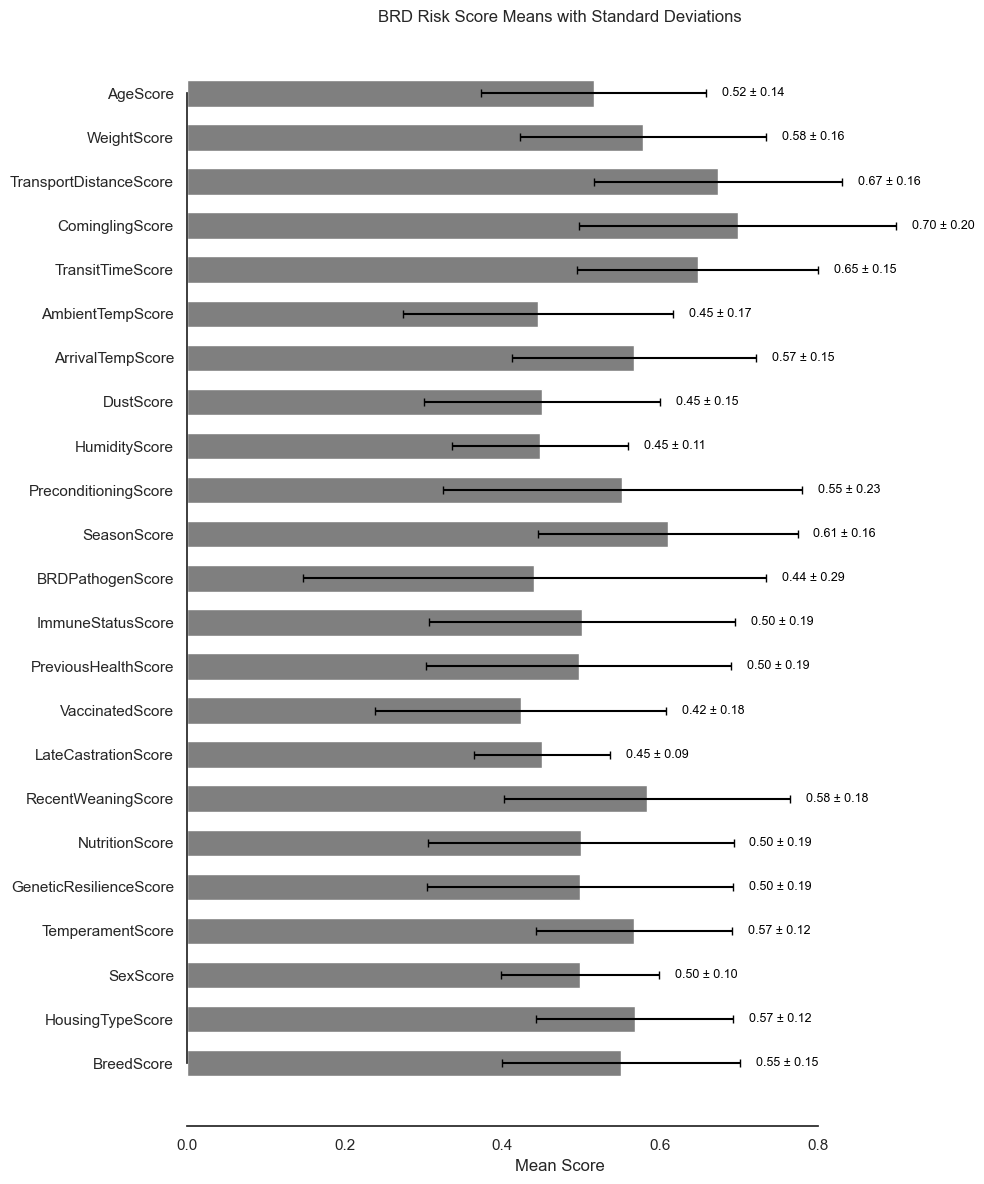

In [9]:

score_labels = [label for label in summary.index if label not in ['BrdRiskIndex', 'BRDRisk']]
summary_plot = summary.loc[score_labels]

sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(10, 12))

y_pos = np.arange(len(summary_plot))
bars = ax.barh(
    y_pos,
    summary_plot['Mean'],
    xerr=summary_plot['Standard Deviation'],
    align='center',
    color='tab:grey',
    ecolor='black',
    capsize=3,
    height=0.6
)

ax.set_yticks(y_pos)
ax.set_yticklabels(summary_plot.index)
ax.invert_yaxis()
ax.set_xlabel('Mean Score')
ax.set_title('BRD Risk Score Means with Standard Deviations')

for i, (mean, std) in enumerate(zip(summary_plot['Mean'], summary_plot['Standard Deviation'])):
    ax.text(mean + std + 0.02, i, f"{mean:.2f} ± {std:.2f}",
            va='center', fontsize=9, color='black')

sns.despine(trim=True)
plt.tight_layout()
plt.show()

In [10]:
risk_score_columns = [
    "AgeScore",
    "WeightScore",
    "TransportDistanceScore",
    "CominglingScore",
    "TransitTimeScore",
    "AmbientTempScore",
    "ArrivalTempScore",
    "DustScore",
    "HumidityScore",
    "PreconditioningScore",
    "SeasonScore",
    "BRDPathogenScore",
    "ImmuneStatusScore",
    "PreviousHealthScore",
    "VaccinatedScore",
    "LateCastrationScore",
    "RecentWeaningScore",
    "NutritionScore",
    "GeneticResilienceScore",
    "TemperamentScore",
    "SexScore",
    "HousingTypeScore",
    "BreedScore",
    "BrdRiskIndex",
    "BRDRisk"
]

present_risk_score_columns = [col for col in risk_score_columns if col in df.columns]

riskscore_meanSD = pd.DataFrame({
    "Mean": df[present_risk_score_columns].mean(),
    "Standard Deviation": df[present_risk_score_columns].std()
})
riskscore_meanSD.to_csv("riskscore_meanSD.csv", index=True)

In [11]:
df.to_csv("Brdrisk_with_scores.csv", index=False)